In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
# Create a specific folder for your research project
save_path = "/content/drive/MyDrive/Research_SLM_Baseline"
if not os.path.exists(save_path):
    os.makedirs(save_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import torch
import gc
# Clear memory
gc.collect()
torch.cuda.empty_cache()

In [3]:
import os
os.environ["RAY_memory_usage_threshold"] = "0.99" # Allow using almost all RAM

In [4]:
# Core FL and ML libraries
!pip install flwr[simulation] torch torchvision transformers datasets peft
# For efficiency during baseline training
!pip install bitsandbytes accelerate

!pip install "protobuf<4.21.0" "ray[default]" flwr

  Using cached pydantic-1.10.26-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (155 kB)
INFO: pip is looking at multiple versions of flwr[simulation] to determine which version is compatible with other requirements. This could take a while.
  Using cached flwr-1.27.0-py3-none-any.whl.metadata (14 kB)
  Using cached cryptography-46.0.6-cp311-abi3-manylinux_2_34_x86_64.whl.metadata (5.7 kB)
  Using cached protobuf-6.33.6-cp39-abi3-manylinux2014_x86_64.whl.metadata (593 bytes)
Using cached cryptography-46.0.6-cp311-abi3-manylinux_2_34_x86_64.whl (4.5 MB)
Using cached protobuf-6.33.6-cp39-abi3-manylinux2014_x86_64.whl (323 kB)
Using cached flwr-1.27.0-py3-none-any.whl (782 kB)
  Attempting uninstall: protobuf
    Found existing installation: protobuf 3.20.3
    Uninstalling protobuf-3.20.3:
      Successfully uninstalled protobuf-3.20.3
  Attempting uninstall: cryptography
    Found existing installation: cryptography 41.0.7
    Uninstalling cryptography-41.0.7:
      

  Using cached protobuf-3.20.3-py2.py3-none-any.whl.metadata (720 bytes)
INFO: pip is looking at multiple versions of flwr to determine which version is compatible with other requirements. This could take a while.
  Using cached flwr-1.26.1-py3-none-any.whl.metadata (14 kB)
  Using cached cryptography-44.0.3-cp39-abi3-manylinux_2_34_x86_64.whl.metadata (5.7 kB)
  Using cached flwr-1.26.0-py3-none-any.whl.metadata (14 kB)
  Using cached flwr-1.25.0-py3-none-any.whl.metadata (14 kB)
  Using cached click-8.1.8-py3-none-any.whl.metadata (2.3 kB)
  Using cached flwr-1.24.0-py3-none-any.whl.metadata (14 kB)
  Using cached flwr-1.23.0-py3-none-any.whl.metadata (14 kB)
  Using cached flwr-1.22.0-py3-none-any.whl.metadata (14 kB)
  Using cached flwr-1.21.0-py3-none-any.whl.metadata (15 kB)
INFO: pip is still looking at multiple versions of flwr to determine which version is compatible with other requirements. This could take a while.
  Using cached flwr-1.20.0-py3-none-any.whl.metadata (15 kB)


In [5]:
import torch
import numpy as np
import random

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    print(f"✅ Seed set to: {seed}")

set_seed(42)

✅ Seed set to: 42


In [6]:
#base model
from transformers import AutoModelForCausalLM, AutoTokenizer
from peft import LoraConfig, get_peft_model

model_id = "TinyLlama/TinyLlama-1.1B-Chat-v1.0"
tokenizer = AutoTokenizer.from_pretrained(model_id)
tokenizer.pad_token = tokenizer.eos_token
# Note: For the baseline, we use standard LoRA (PEFT) to make training feasible
lora_config = LoraConfig(r=8, lora_alpha=32, target_modules=["q_proj", "v_proj"], task_type="CAUSAL_LM")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


In [7]:
import torch
import flwr as fl
from collections import OrderedDict

class SLMClient(fl.client.NumPyClient):
    def __init__(self, model, train_loader, val_loader, device):
        self.model = model
        self.train_loader = train_loader
        self.val_loader = val_loader
        self.device = device

    def get_parameters(self, config):
        """Returns only the trainable LoRA parameters (Detached)."""
        # FIXED LINE BELOW: Added .detach()
        return [val.detach().cpu().numpy() for name, val in self.model.named_parameters() if val.requires_grad]

    def set_parameters(self, parameters):
        """Loads parameters into the trainable LoRA layers."""
        params_dict = zip([name for name, val in self.model.named_parameters() if val.requires_grad], parameters)
        state_dict = OrderedDict({k: torch.tensor(v).to(self.device) for k, v in params_dict})
        self.model.load_state_dict(state_dict, strict=False)

    def fit(self, parameters, config):
        self.set_parameters(parameters)
        self.model.train()

        # Use AdamW for better LLM stability
        optimizer = torch.optim.AdamW(self.model.parameters(), lr=2e-4)

        print(f"  [Client] Training on {len(self.train_loader)} batches...")
        for batch in self.train_loader:
            # Move entire batch to GPU/CPU
            batch = {k: v.to(self.device) for k, v in batch.items()}

            optimizer.zero_grad()
            outputs = self.model(**batch)
            loss = outputs.loss
            loss.backward()
            optimizer.step()

        print("  [Client] Training complete.")
        return self.get_parameters(config={}), len(self.train_loader.dataset), {}

    def evaluate(self, parameters, config):
        self.set_parameters(parameters)
        self.model.eval()
        total_loss = 0.0

        with torch.no_grad():
            for batch in self.val_loader:
                batch = {k: v.to(self.device) for k, v in batch.items()}
                outputs = self.model(**batch)
                total_loss += outputs.loss.item()

        # In LLM research, we often use Perplexity (exp of loss) instead of Accuracy
        return float(total_loss / len(self.val_loader)), len(self.val_loader.dataset), {}

In [8]:
from transformers import DataCollatorForLanguageModeling

def prepare_dataloaders(partition, tokenizer, batch_size=2):
    """
    Generalized data preparer that takes any Hugging Face partition
    and returns PyTorch Loaders.
    """
    def tokenize_function(examples):
        return tokenizer(examples["text"], truncation=True, max_length=256, padding="max_length")

    tokenized_dataset = partition.map(tokenize_function, batched=True, remove_columns=partition.column_names)

    # Data collator handles dynamic padding for LLMs
    data_collator = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm=False)

    train_loader = torch.utils.data.DataLoader(
        tokenized_dataset, batch_size=batch_size, collate_fn=data_collator
    )
    return train_loader

In [9]:
import ray
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
from peft import LoraConfig, get_peft_model
from datasets import load_dataset

# This prevents 'Actor' errors and ensures the simulation can restart if it crashes
ray.init(ignore_reinit_error=True, num_cpus=2, include_dashboard=False)

# 1. SETUP (Always First)
device = "cuda" if torch.cuda.is_available() else "cpu"

# 2. MODEL LOADING
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
)

base_model = AutoModelForCausalLM.from_pretrained(
    model_id,
    quantization_config=bnb_config,
    device_map="auto" # Let transformers handle the T4 mapping
)

config = LoraConfig(
    r=8,
    lora_alpha=32,
    target_modules=["q_proj", "v_proj"],
    task_type="CAUSAL_LM"
)
model = get_peft_model(base_model, config)

2026-04-01 07:58:43,813	INFO worker.py:2012 -- Started a local Ray instance.
/usr/local/lib/python3.12/dist-packages/ray/_private/worker.py:2051: FutureWarning: Tip: In future versions of Ray, Ray will no longer override accelerator visible devices env var if num_gpus=0 or num_gpus=None (default). To enable this behavior and turn off this error message, set RAY_ACCEL_ENV_VAR_OVERRIDE_ON_ZERO=0
  warnings.warn(
(pid=gcs_server) [2026-04-01 07:59:02,176 E 23533 23533] (gcs_server) gcs_server.cc:302: Failed to establish connection to the event+metrics exporter agent. Events and metrics will not be exported. Exporter agent status: RpcError: Running out of retries to initialize the metrics agent. rpc_code: 14


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [10]:
# 3. DATA & CLIENT LOGIC (Referencing the model above)
dataset = load_dataset("wikitext", "wikitext-2-raw-v1", split="train")
dataset = dataset.select(range(10000))
dataset = dataset.filter(lambda x: len(x["text"]) > 10)   #filter empty lines for better training
partition_size = len(dataset) // 5  # Assuming 5 clients

def client_fn(cid: str):
    """
    Create a Flower client representing a single device.
    'cid' is the unique ID for the client (0, 1, 2...).
    """
    # Load model ONLY when the client is spawned
    bnb_config = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16)

    # This ensures the model is loaded into the Virtual Client's memory space, not the main script
    base_model = AutoModelForCausalLM.from_pretrained(
        model_id,
        quantization_config=bnb_config,
        device_map="auto"
    )
    model = get_peft_model(base_model, lora_config)

    # Create the local partition for this specific client
    idx = int(cid)
    start_idx = idx * partition_size
    end_idx = (idx + 1) * partition_size
    # client_partition = dataset.select(range(start_idx, end_idx))
    client_partition = dataset.select(range(start_idx, start_idx + 100)) # Only 100 rows per client # Select a very small slice for the first test run

    # Split into train/val (90/10)
    client_partition = client_partition.train_test_split(test_size=0.1)
    # Prepare DataLoaders using the generalized function we discussed
    train_loader = prepare_dataloaders(client_partition["train"], tokenizer)
    val_loader = prepare_dataloaders(client_partition["test"], tokenizer)

    # Return the SLMClient instance
    # Note: 'model' and 'device' should be defined in your main script scope
    return SLMClient(model, train_loader, val_loader, device)

In [11]:
# Optimization Engine (Quantization & Pruning)
import torch.nn.utils.prune as prune
import torch

def apply_optimization_engine(parameters_ndarrays, pruning_amount=0.1):
    """
    Simulates the Optimization Engine on the Central Server.
    It takes the aggregated NumPy weights and applies pruning.
    """
    # 1. Convert NumPy arrays back to PyTorch Tensors for pruning
    tensors = [torch.from_numpy(np_arr) for np_arr in parameters_ndarrays]

    optimized_tensors = []
    for t in tensors:
        # Only prune multidimensional weights (skip biases/scalars)
        if len(t.shape) > 1:
            # Simple Magnitude Pruning: zero out the smallest X% of weights
            # This satisfies the "Quantization & Pruning" block in your diagram
            flat_t = t.view(-1)
            threshold = torch.quantile(torch.abs(flat_t), pruning_amount)
            mask = torch.abs(t) > threshold
            t = t * mask
        optimized_tensors.append(t.numpy())

    return optimized_tensors

In [12]:
from flwr.server.strategy import FedAvg
from flwr.common import ndarrays_to_parameters, parameters_to_ndarrays

class OptimizedFedAvg(FedAvg):
    def aggregate_fit(self, server_round, results, failures):
        # Call the standard FedAvg aggregation first
        aggregated_parameters, aggregated_metrics = super().aggregate_fit(server_round, results, failures)

        if aggregated_parameters is not None:
            # Convert parameters to ndarrays
            ndarrays = parameters_to_ndarrays(aggregated_parameters)

            # --- INNOVATION START: Optimization Engine ---
            print(f"Round {server_round}: Applying Optimization Engine (Pruning)...")
            optimized_ndarrays = apply_optimization_engine(ndarrays, pruning_amount=0.1)
            # --- INNOVATION END ---

            aggregated_parameters = ndarrays_to_parameters(optimized_ndarrays)

        return aggregated_parameters, aggregated_metrics

In [13]:
# Plotting Functions
import matplotlib.pyplot as plt

def plot_federated_learning_results(history_proposed):
    """
    Visualizes the training loss over federated rounds.
    """
    # Extracting loss from history
    rounds, losses = zip(*history_proposed.losses_distributed)

    plt.figure(figsize=(10, 6))
    plt.plot(rounds, losses, marker='o', linestyle='-', color='b', label='Baseline (FedAvg)')
    plt.title('Federated Learning Training Loss (TinyLlama Baseline)')
    plt.xlabel('Federated Round')
    plt.ylabel('Distributed Loss')
    plt.grid(True)
    plt.legend()

    # Save the plot for your thesis/report
    plt.savefig("federated_learning_loss.png")
    plt.show()

INFO flwr 2026-04-01 07:59:14,789 | app.py:178 | Starting Flower simulation, config: ServerConfig(num_rounds=5, round_timeout=None)
INFO:flwr:Starting Flower simulation, config: ServerConfig(num_rounds=5, round_timeout=None)
2026-04-01 07:59:28,387	INFO worker.py:2012 -- Started a local Ray instance.
INFO flwr 2026-04-01 07:59:42,551 | app.py:213 | Flower VCE: Ray initialized with resources: {'node:__internal_head__': 1.0, 'object_store_memory': 3956181811.0, 'accelerator_type:T4': 1.0, 'node:172.28.0.12': 1.0, 'GPU': 1.0, 'memory': 9231090893.0, 'CPU': 2.0}
INFO:flwr:Flower VCE: Ray initialized with resources: {'node:__internal_head__': 1.0, 'object_store_memory': 3956181811.0, 'accelerator_type:T4': 1.0, 'node:172.28.0.12': 1.0, 'GPU': 1.0, 'memory': 9231090893.0, 'CPU': 2.0}
INFO flwr 2026-04-01 07:59:42,556 | app.py:219 | Optimize your simulation with Flower VCE: https://flower.dev/docs/framework/how-to-run-simulations.html
INFO:flwr:Optimize your simulation with Flower VCE: https:

(DefaultActor pid=24199)   [Client] Training on 45 batches...
(DefaultActor pid=24199)   [Client] Training complete.


Map: 100%|██████████| 10/10 [00:00<00:00, 1274.48 examples/s]


(DefaultActor pid=24199)   [Client] Training on 45 batches...
(DefaultActor pid=24199)   [Client] Training complete.


(DefaultActor pid=24199) Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
Map: 100%|██████████| 10/10 [00:00<00:00, 1266.01 examples/s]


(DefaultActor pid=24199)   [Client] Training on 45 batches...
(DefaultActor pid=24199)   [Client] Training complete.


... (52 outputs left out)

DEBUG flwr 2026-04-01 08:09:08,681 | server.py:236 | fit_round 5 received 5 results and 0 failures
DEBUG:flwr:fit_round 5 received 5 results and 0 failures


(DefaultActor pid=24199)   [Client] Training complete.
Round 5: Applying Optimization Engine (Pruning)...


DEBUG flwr 2026-04-01 08:09:08,922 | server.py:173 | evaluate_round 5: strategy sampled 5 clients (out of 5)
DEBUG:flwr:evaluate_round 5: strategy sampled 5 clients (out of 5)
Loading weights:  92%|█████████▏| 184/201 [00:00<00:00, 125.32it/s, Materializing param=model.layers.20.mlp.down_proj.weight]  
Loading weights:  92%|█████████▏| 184/201 [00:00<00:00, 125.32it/s, Materializing param=model.layers.20.mlp.down_pro
Map: 100%|██████████| 10/10 [00:00<00:00, 561.25 examples/s]
DEBUG flwr 2026-04-01 08:09:23,622 | server.py:187 | evaluate_round 5 received 5 results and 0 failures
DEBUG:flwr:evaluate_round 5 received 5 results and 0 failures
INFO flwr 2026-04-01 08:09:23,626 | server.py:153 | FL finished in 546.09883377
INFO:flwr:FL finished in 546.09883377
INFO flwr 2026-04-01 08:09:23,632 | app.py:226 | app_fit: losses_distributed [(1, 2.3328742933273316), (2, 2.3606917381286623), (3, 2.3179583072662355), (4, 2.2590567827224732), (5, 2.189824378490448)]
INFO:flwr:app_fit: losses_distri

✅ Phase 1 Baseline Results Saved!


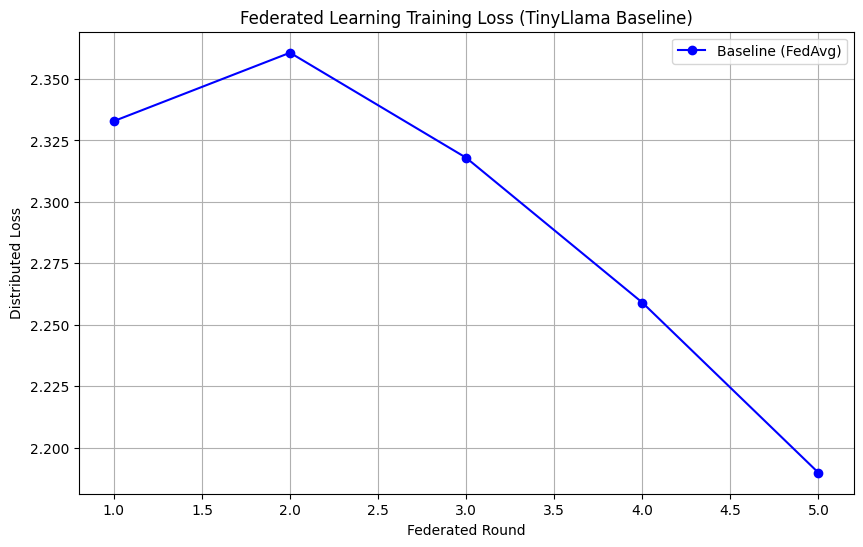

In [14]:
import pandas as pd
import numpy as np
import flwr as fl

# 1. Define the Strategy
strategy = OptimizedFedAvg(
    fraction_fit=1.0,
    fraction_evaluate=1.0,
    min_fit_clients=5,
    min_available_clients=5,
)

# 2. Start the Simulation (This runs all 5 rounds automatically)
history_proposed = fl.simulation.start_simulation(
    client_fn=client_fn,
    num_clients=5,
    config=fl.server.ServerConfig(num_rounds=5),
    strategy=strategy,
    client_resources={"num_gpus": 0.9, "num_cpus": 2} # Good for T4 GPU
)

# 3. Extract metrics from the 'history' object
# Flower stores results in history.losses_distributed
results_log = []
for r, loss in history_proposed.losses_distributed:
    stats = {
        "round": r,
        "loss": loss,
        "perplexity": np.exp(loss),
        # Note: comm_size and gpu_usage are harder to grab post-simulation
        # You should log those inside your Strategy or Client class for Phase 2
    }
    results_log.append(stats)

# 4. Save to CSV
df = pd.DataFrame(results_log)
df.to_csv("phase1_baseline_results.csv", index=False)
print("✅ Phase 1 Baseline Results Saved!")
plot_federated_learning_results(history_proposed)

In [15]:
def save_lora_adapters(model, folder_name="baseline_round_3"):
    """
    Saves the LoRA adapter weights and configuration to Google Drive.
    """
    full_path = os.path.join(save_path, folder_name)

    # Save the adapter weights and the config file
    model.save_pretrained(full_path)

    # Also save the tokenizer so you can run inference easily later
    tokenizer.save_pretrained(full_path)

    print(f"✅ LoRA adapters successfully saved to: {full_path}")

# Execute saving after the simulation ends
save_lora_adapters(model)

✅ LoRA adapters successfully saved to: /content/drive/MyDrive/Research_SLM_Baseline/baseline_round_3


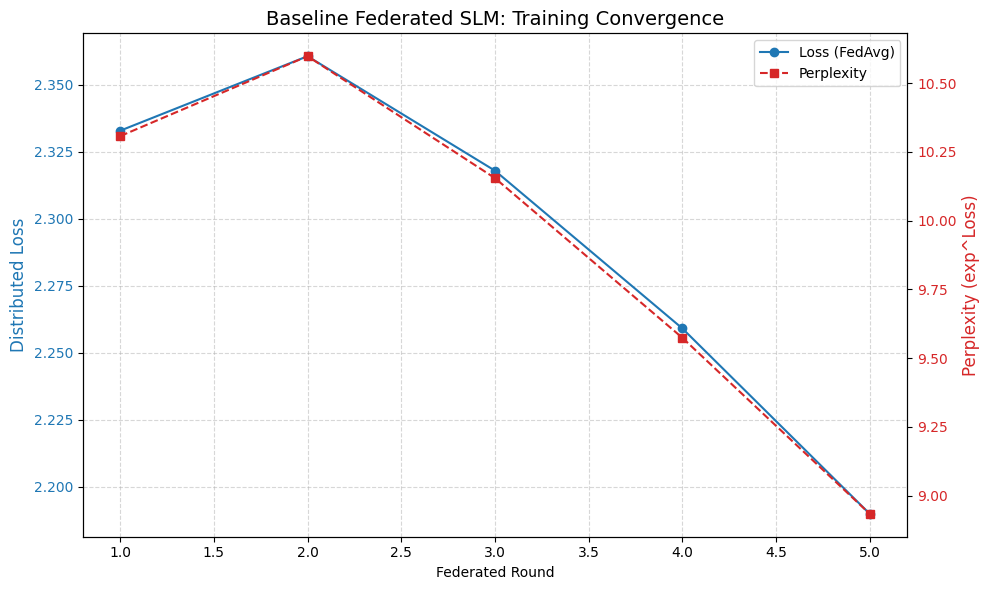

In [16]:
import matplotlib.pyplot as plt
import numpy as np

def plot_baseline_metrics(history_proposed):
    """
    Plots both Distributed Loss and Perplexity on a dual-axis graph.
    """
    # Extract data from Flower history
    rounds, losses = zip(*history_proposed.losses_distributed)

    # Calculate Perplexity: e^Loss
    perplexities = [np.exp(l) for l in losses]

    fig, ax1 = plt.subplots(figsize=(10, 6))

    # --- Axis 1: Distributed Loss ---
    color_loss = 'tab:blue'
    ax1.set_xlabel('Federated Round')
    ax1.set_ylabel('Distributed Loss', color=color_loss, fontsize=12)
    ax1.plot(rounds, losses, marker='o', linestyle='-', color=color_loss, label='Loss (FedAvg)')
    ax1.tick_params(axis='y', labelcolor=color_loss)
    ax1.grid(True, which='both', linestyle='--', alpha=0.5)

    # --- Axis 2: Perplexity ---
    ax2 = ax1.twinx()  # Create a second y-axis that shares the same x-axis
    color_ppl = 'tab:red'
    ax2.set_ylabel('Perplexity (exp^Loss)', color=color_ppl, fontsize=12)
    ax2.plot(rounds, perplexities, marker='s', linestyle='--', color=color_ppl, label='Perplexity')
    ax2.tick_params(axis='y', labelcolor=color_ppl)

    # Final touches
    plt.title('Baseline Federated SLM: Training Convergence', fontsize=14)
    fig.tight_layout()

    # Add a combined legend
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right')

    plt.savefig("baseline_metrics_dual_axis.png")
    plt.show()

# Run the updated visualization
plot_baseline_metrics(history_proposed)